# 현실의 데이터 19: 미세먼지 예보

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/19_air_quality.ipynb)

**분야**: 도시 · 공간 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 환경 · 기상 서비스 · 시계열 예측 · 경보

> 내일 이 시각 초미세먼지 (PM2.5) 는 얼마일까?

**데이터**: UCI Beijing PM2.5 (약 2MB). Liang et al. (2015). 베이징 미국 대사관 측정소의 2010~2014 시간별 PM2.5 (㎍/㎥) + 이슬점 · 기온 · 기압 · 풍향 · 풍속 · 눈 · 비 (43,824시간).

인턴 · 산학협력 과제에서 처음 받게 될 데이터와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 한 시간 |
| ② 입력 X | 지금 PM2.5 · 지난 몇 시간 · 기온 · 바람 · 습도 · 달 · 시각 |
| ③ 출력 y | 24시간 뒤 PM2.5 (㎍/㎥) |
| ④ 평가지표 | MAE, '매우 나쁨' (76 이상) 재현율 |
| ⑤ 기준선 | 지금 값 그대로 |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [Liang et al. (2015) Assessing Beijing's PM2.5 pollution: severity, weather impact, APEC and winter heating, Proc. R. Soc. A](https://doi.org/10.1098/rspa.2015.0257)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

In [2]:
URL = "https://archive.ics.uci.edu/static/public/381/beijing+pm2+5+data.zip"
with zipfile.ZipFile(download(URL, "data/beijing_pm25.zip")) as z:
    df = pd.read_csv(z.open(z.namelist()[0]))
df["time"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
df = df.set_index("time").rename(columns={"pm2.5": "pm25"})
print(df.shape, df.index.min(), "~", df.index.max())
print(f"missing PM2.5: {df['pm25'].isna().mean():.1%}")
df.sample(5, random_state=0)

(43824, 13) 2010-01-01 00:00:00 ~ 2014-12-31 23:00:00
missing PM2.5: 4.7%


,No,year,month,day,hour,pm25,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
time,,,,,,,,,,,,,
2010-11-25 23:00:00,7896,2010,11,25,23,168.0,-10,-3.0,1024.0,NW,1.79,0,0
2013-01-18 09:00:00,26722,2013,1,18,9,82.0,-12,-8.0,1029.0,NW,6.26,0,0
2013-01-27 01:00:00,26930,2013,1,27,1,307.0,-8,-5.0,1030.0,NE,0.89,0,0
2014-11-06 17:00:00,42498,2014,11,6,17,6.0,-13,9.0,1030.0,NE,59.90,0,0
2014-05-20 04:00:00,38405,2014,5,20,4,197.0,15,18.0,1003.0,NW,1.79,0,0


## 열어 보기

달마다 · 시각마다 평균. 겨울 난방철에 높을까?

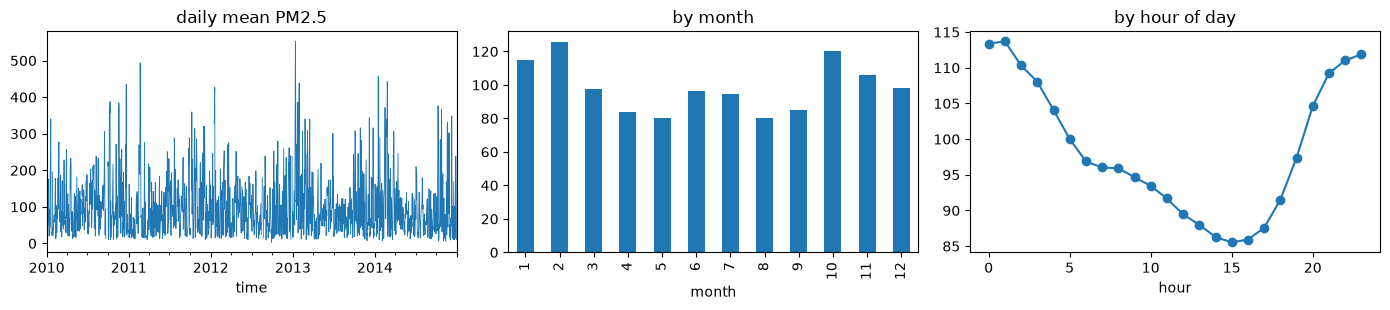

hours at 'very bad' (>= 76): 46.2%


In [3]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.2))
df["pm25"].resample("D").mean().plot(ax=axs[0], lw=0.6, title="daily mean PM2.5")
df.groupby("month")["pm25"].mean().plot(kind="bar", ax=axs[1], title="by month")
df.groupby("hour")["pm25"].mean().plot(ax=axs[2], marker="o", title="by hour of day")
plt.tight_layout(); plt.show()
print(f"hours at 'very bad' (>= 76): {(df['pm25'] >= 76).mean():.1%}")

## 문제 하나 골라 보기: 지금까지 → 24시간 뒤 PM2.5

**시간 순서** 로 나눈다: 2010~2013 학습, 2014 시험. 입력은 '지금' 알 수 있는 것만. 기준선 = 지금 값 그대로.

In [4]:
from sklearn.ensemble import HistGradientBoostingRegressor

def recall_at(y_true, y_pred, th=76):
    hit = y_true >= th
    return np.mean(y_pred[hit] >= th)

d = df.copy()
for k in (1, 2, 3, 24):
    d[f"pm_lag{k}"] = d["pm25"].shift(k)
d["target"] = d["pm25"].shift(-24)
d = pd.get_dummies(d, columns=["cbwd"], dtype=float).dropna(subset=["pm25", "target"])
feats = [c for c in d.columns if c.startswith(("pm_", "cbwd_"))] + ["pm25", "DEWP", "TEMP", "PRES", "Iws", "Is", "Ir", "month", "hour"]
tr, te = d[d["year"] < 2014], d[d["year"] == 2014]
m = HistGradientBoostingRegressor(random_state=0).fit(tr[feats], tr["target"])
for name, pred in [("same as now", te["pm25"].values), ("train mean", np.full(len(te), tr["target"].mean())), ("gradient boosting", m.predict(te[feats]))]:
    print(f"{name:18s} MAE {np.mean(np.abs(pred - te['target'])):.1f}  recall of 'very bad' {recall_at(te['target'].values, pred):.0%}")

same as now        MAE 67.4  recall of 'very bad' 61%
train mean         MAE 69.0  recall of 'very bad' 100%
gradient boosting  MAE 59.9  recall of 'very bad' 84%


**관찰**: 하루 뒤는 지금 값만으로는 잘 맞지 않는다. 바람이 바뀌면 하루 만에 공기가 바뀌기 때문이다. 실제 예보는 **내일의 기상 예보** (바람 · 비) 를 입력으로 쓴다.

## 다른 문제로 바꿔 보기

- 한국 데이터: 에어코리아 측정소 (공공데이터포털 API 신청). 한 행 = 측정소 × 시간이면 이웃 측정소 · 중국 쪽 바람이 입력이 된다 (시공간 문제).
- '농도' 대신 '내일 마스크가 필요한가 (나쁨 이상)' 를 맞히면 분류가 된다. 지표는?

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |